# Data Exploration

Marketing channel performance analysis for budget allocation across a $500K monthly marketing budget.

## Dataset choice

**Name:** Global Ads Performance (Google, Meta, TikTok)

**Source:** Kaggle

**URL:** https://www.kaggle.com/datasets/nudratabbas/global-ads-performance-google-meta-tiktok

**Why I picked it:**

- It has 3 real advertising platforms as groups to compare: Google Ads, Meta Ads, and TikTok Ads. This is close to a real marketing budget allocation problem, just like the scenario in this lab.
- It includes all the raw numbers I need: impressions, clicks, conversions, ad spend, and revenue. Not just pre computed rates. This matters because Fisher's exact test needs raw conversion counts, not a conversion rate.
- It has 1800 rows spread across the 3 platforms (720 Google, 630 Meta, 450 TikTok), which is a good sample size for statistical testing.
- The data is daily and covers the year 2024, so it works well for the power analysis part later, where I look at how many days of data I would need.
- The dataset author generated the values to have realistic relationships between these metrics (for example, spend going up with impressions), so the statistical patterns should behave in a reasonable way.

**Note on authenticity:** this is a real, publicly hosted Kaggle dataset (not something I made up), but its values are synthetically generated by the dataset author to reflect realistic ad performance relationships. This is standard practice for public marketing datasets, since real advertiser account exports are almost never published for privacy and competitive reasons. I cover this as a caveat in the executive memo.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)

## Load the dataset

In [2]:
df = pd.read_csv('data/raw/global_ads_performance_dataset.csv')

print('Shape:', df.shape)
print('\nColumns:', df.columns.tolist())
print('\nData types:')
print(df.dtypes)
df.head()

Shape: (1800, 14)

Columns: ['date', 'platform', 'campaign_type', 'industry', 'country', 'impressions', 'clicks', 'CTR', 'CPC', 'ad_spend', 'conversions', 'CPA', 'revenue', 'ROAS']

Data types:
date                 str
platform             str
campaign_type        str
industry             str
country              str
impressions        int64
clicks             int64
CTR              float64
CPC              float64
ad_spend         float64
conversions        int64
CPA              float64
revenue          float64
ROAS             float64
dtype: object


,date,platform,campaign_type,industry,country,impressions,clicks,CTR,CPC,ad_spend,conversions,CPA,revenue,ROAS
0,2024-01-21,Google Ads,Search,Fintech,UAE,59886,2113,0.0353,1.26,2662.38,159,16.74,4803.43,1.80
1,2024-01-22,TikTok Ads,Search,EdTech,UK,135608,5220,0.0385,1.18,6159.60,411,14.99,64126.68,10.41
2,2024-06-15,TikTok Ads,Video,Healthcare,USA,92313,5991,0.0649,0.85,5092.35,267,19.07,10489.07,2.06
3,2024-01-02,TikTok Ads,Shopping,SaaS,Germany,83953,5935,0.0707,1.32,7834.20,296,26.47,50505.07,6.45
4,2024-02-22,TikTok Ads,Search,Healthcare,UK,91807,4489,0.0489,1.93,8663.77,107,80.97,3369.53,0.39


## Explore the data structure

Here I check the grouping variable, what metrics are available, and the general data quality (missing values, types, duplicates, date range).

In [3]:
print('Missing values per column:')
print(df.isna().sum())
print()
print('Duplicated rows:', df.duplicated().sum())
print()
print('Date range:', df['date'].min(), 'to', df['date'].max())
print()
print('Groups (platform):', df['platform'].unique().tolist())
print()
print('Rows per platform:')
print(df['platform'].value_counts())

Missing values per column:
date             0
platform         0
campaign_type    0
industry         0
country          0
impressions      0
clicks           0
CTR              0
CPC              0
ad_spend         0
conversions      0
CPA              0
revenue          0
ROAS             0
dtype: int64

Duplicated rows: 0

Date range: 2024-01-01 to 2024-12-30

Groups (platform): ['Google Ads', 'TikTok Ads', 'Meta Ads']

Rows per platform:
platform
Google Ads    720
Meta Ads      630
TikTok Ads    450
Name: count, dtype: int64


**Grouping variable:** `platform` (Google Ads, Meta Ads, TikTok Ads). This is what I compare across the whole lab.

**Metrics already in the data:** impressions, clicks, conversions, ad_spend, revenue, and pre computed CTR, CPC, CPA, ROAS.

**Data quality:** no missing values, no duplicated rows, no zero values in the key columns. The data covers the full year 2024.

There are also some extra dimension columns (campaign_type, industry, country) which are not my main grouping variable, but I check them below just to understand the data better.

In [4]:
print('campaign_type:', df['campaign_type'].unique().tolist())
print('industry:', df['industry'].unique().tolist())
print('country:', df['country'].unique().tolist())
print()
print('rows per platform per date (how many campaign rows share the same platform+date):')
print(df.groupby(['platform', 'date']).size().value_counts().sort_index())

campaign_type: ['Search', 'Video', 'Shopping', 'Display']
industry: ['Fintech', 'EdTech', 'Healthcare', 'SaaS', 'E-commerce']
country: ['UAE', 'UK', 'USA', 'Germany', 'Canada', 'India', 'Australia']

rows per platform per date (how many campaign rows share the same platform+date):
1    341
2    293
3    132
4     68
5     30
6      8
7      1
Name: count, dtype: int64


So for a given platform and date, there can be more than one row (different campaign_type / industry / country combos running the same day). To get a clean daily time series per channel, which I will need later for the power analysis part, I aggregate the data to one row per platform per day.

## Prepare the data for analysis

In [5]:
df['date'] = pd.to_datetime(df['date'])

daily = (
    df.groupby(['platform', 'date'], as_index=False)
    .agg(
        impressions=('impressions', 'sum'),
        clicks=('clicks', 'sum'),
        conversions=('conversions', 'sum'),
        ad_spend=('ad_spend', 'sum'),
        revenue=('revenue', 'sum'),
    )
    .sort_values(['platform', 'date'])
    .reset_index(drop=True)
)

# recompute rate metrics from the summed raw numbers, do not just average the per row rates
daily['CTR'] = daily['clicks'] / daily['impressions']
daily['conversion_rate'] = daily['conversions'] / daily['clicks']
daily['CPA'] = daily['ad_spend'] / daily['conversions']
daily['ROAS'] = daily['revenue'] / daily['ad_spend']

# a channel with zero cost or zero clicks would give inf here, replace with NaN so it does not break the stats later
daily = daily.replace([np.inf, -np.inf], np.nan)

print('Shape after daily aggregation:', daily.shape)
daily.head()

Shape after daily aggregation: (873, 11)


,platform,date,impressions,clicks,conversions,ad_spend,revenue,CTR,conversion_rate,CPA,ROAS
0,Google Ads,2024-01-01,21702,1000,17,3170.00,3670.88,0.046079,0.017000,186.470588,1.158006
1,Google Ads,2024-01-04,162825,7382,452,19953.23,24924.40,0.045337,0.061230,44.144314,1.249141
2,Google Ads,2024-01-05,196692,6264,310,15668.95,64727.90,0.031847,0.049489,50.545000,4.130966
3,Google Ads,2024-01-06,139158,3061,118,3887.47,15835.46,0.021997,0.038549,32.944661,4.073462
4,Google Ads,2024-01-07,238097,9087,340,21959.64,49123.74,0.038165,0.037416,64.587176,2.237001


In [6]:
daily.to_csv('data/marketing_data.csv', index=False)
print('Saved cleaned dataset to data/marketing_data.csv')

Saved cleaned dataset to data/marketing_data.csv


**Transformations made:**

- Converted `date` to a real datetime type.
- Aggregated the raw data to one row per platform per day (summed impressions, clicks, conversions, ad_spend, revenue for rows that shared the same platform and date).
- Recomputed CTR, conversion rate, CPA, and ROAS from the summed daily totals, instead of just keeping the original per campaign rates. This is more correct once I aggregate.
- Replaced infinite values (which would happen for a day with zero clicks or zero spend) with NaN.
- Saved the result as `data/marketing_data.csv`, this is the file used for the rest of the analysis.

In [7]:
print('Number of groups:', daily['platform'].nunique())
print()
print('Sample size (days) per group:')
print(daily['platform'].value_counts())
print()
print('Date range:', daily['date'].min().date(), 'to', daily['date'].max().date())
print()
print('Missing values after cleaning:')
print(daily.isna().sum())

Number of groups: 3

Sample size (days) per group:
platform
Meta Ads      308
Google Ads    307
TikTok Ads    258
Name: count, dtype: int64

Date range: 2024-01-01 to 2024-12-30

Missing values after cleaning:
platform           0
date               0
impressions        0
clicks             0
conversions        0
ad_spend           0
revenue            0
CTR                0
conversion_rate    0
CPA                0
ROAS               0
dtype: int64


## Calculate key marketing metrics

Now I look at each channel as a whole: total spend, total conversions, and the derived metrics (CTR, conversion rate, CPA, ROAS, profit, profit margin). This gives me the first picture of which channel looks stronger before I run any statistical test.

In [8]:
summary = (
    daily.groupby('platform', as_index=False)
    .agg(
        impressions=('impressions', 'sum'),
        clicks=('clicks', 'sum'),
        conversions=('conversions', 'sum'),
        cost=('ad_spend', 'sum'),
        revenue=('revenue', 'sum'),
    )
)

summary['CTR'] = summary['clicks'] / summary['impressions']
summary['conversion_rate'] = summary['conversions'] / summary['clicks']
summary['CPA'] = summary['cost'] / summary['conversions']
summary['ROAS'] = summary['revenue'] / summary['cost']
summary['profit'] = summary['revenue'] - summary['cost']
summary['profit_margin'] = summary['profit'] / summary['revenue']

summary = summary.replace([np.inf, -np.inf], np.nan)

summary_display = summary.round(2)
summary_display

,platform,impressions,clicks,conversions,cost,revenue,CTR,conversion_rate,CPA,ROAS,profit,profit_margin
0,Google Ads,73801150,2936149,131098,6349268.91,22033744.95,0.04,0.04,48.43,3.47,15684476.04,0.71
1,Meta Ads,64403494,1596736,73262,2106061.67,11926045.79,0.02,0.05,28.75,5.66,9819984.12,0.82
2,TikTok Ads,47049590,2599931,122452,2653418.51,20223540.07,0.06,0.05,21.67,7.62,17570121.56,0.87


### Visualize channel level metrics

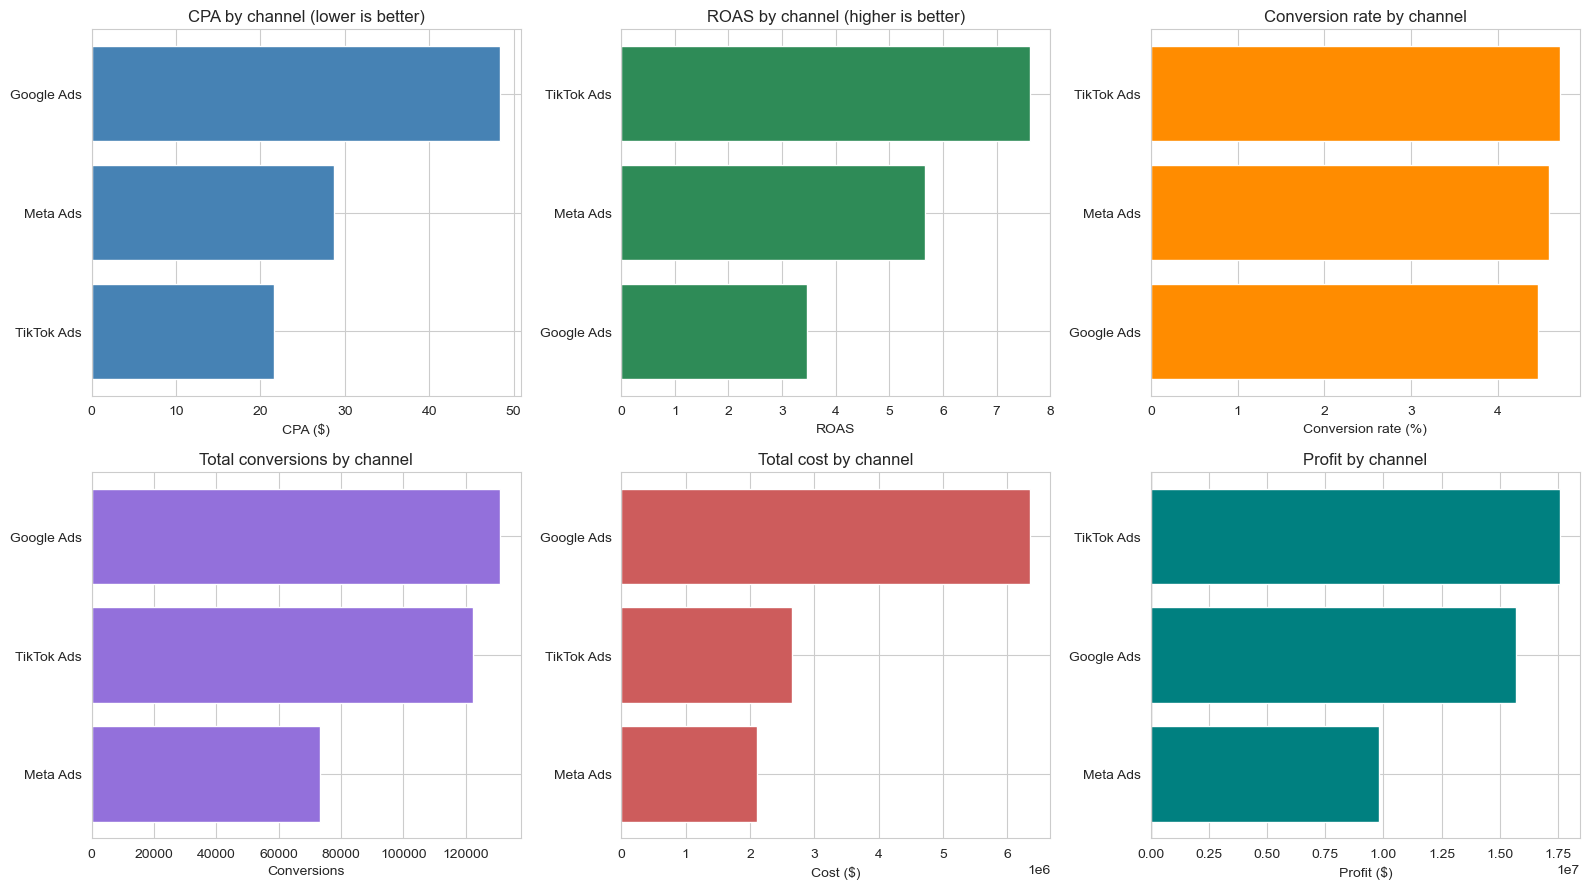

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

plot_summary = summary.sort_values('CPA')
axes[0].barh(plot_summary['platform'], plot_summary['CPA'], color='steelblue')
axes[0].set_title('CPA by channel (lower is better)')
axes[0].set_xlabel('CPA ($)')

plot_summary = summary.sort_values('ROAS')
axes[1].barh(plot_summary['platform'], plot_summary['ROAS'], color='seagreen')
axes[1].set_title('ROAS by channel (higher is better)')
axes[1].set_xlabel('ROAS')

plot_summary = summary.sort_values('conversion_rate')
axes[2].barh(plot_summary['platform'], plot_summary['conversion_rate'] * 100, color='darkorange')
axes[2].set_title('Conversion rate by channel')
axes[2].set_xlabel('Conversion rate (%)')

plot_summary = summary.sort_values('conversions')
axes[3].barh(plot_summary['platform'], plot_summary['conversions'], color='mediumpurple')
axes[3].set_title('Total conversions by channel')
axes[3].set_xlabel('Conversions')

plot_summary = summary.sort_values('cost')
axes[4].barh(plot_summary['platform'], plot_summary['cost'], color='indianred')
axes[4].set_title('Total cost by channel')
axes[4].set_xlabel('Cost ($)')

plot_summary = summary.sort_values('profit')
axes[5].barh(plot_summary['platform'], plot_summary['profit'], color='teal')
axes[5].axvline(0, color='black', linewidth=0.8)
axes[5].set_title('Profit by channel')
axes[5].set_xlabel('Profit ($)')

plt.tight_layout()
plt.savefig('group_metrics_overview.png', dpi=150, bbox_inches='tight')
plt.show()

### Examine distributions

The summary table above only shows totals. Since I have daily data per channel, I can also look at the day to day variability, which matters for the statistical tests in the next notebook.

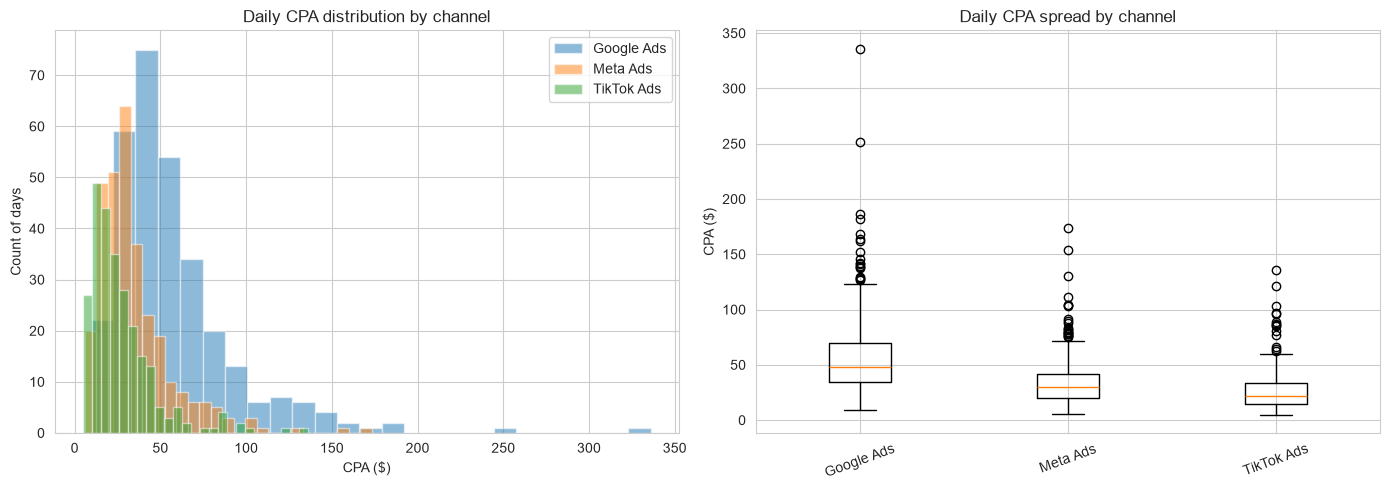

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for platform in daily['platform'].unique():
    subset = daily[daily['platform'] == platform]['CPA'].dropna()
    axes[0].hist(subset, bins=25, alpha=0.5, label=platform)
axes[0].set_title('Daily CPA distribution by channel')
axes[0].set_xlabel('CPA ($)')
axes[0].set_ylabel('Count of days')
axes[0].legend()

box_data = [daily[daily['platform'] == p]['CPA'].dropna() for p in daily['platform'].unique()]
axes[1].boxplot(box_data, tick_labels=daily['platform'].unique())
axes[1].set_title('Daily CPA spread by channel')
axes[1].set_ylabel('CPA ($)')
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.savefig('group_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

In [11]:
print('Day to day CPA variability by channel (standard deviation):')
print(daily.groupby('platform')['CPA'].std().round(2))
print()
print('Day to day ROAS variability by channel (standard deviation):')
print(daily.groupby('platform')['ROAS'].std().round(2))

Day to day CPA variability by channel (standard deviation):
platform
Google Ads    37.14
Meta Ads      22.62
TikTok Ads    19.77
Name: CPA, dtype: float64

Day to day ROAS variability by channel (standard deviation):
platform
Google Ads    2.82
Meta Ads      5.84
TikTok Ads    7.68
Name: ROAS, dtype: float64


### Key insights from this first look

- **TikTok Ads** looks the strongest on unit economics: lowest CPA (about \$21.7) and highest ROAS (about 7.6). It also has the highest CTR (5.5%) and conversion rate (4.7%), though the differences in conversion rate between channels are small.
- **Google Ads** has the highest CPA (about \$48.4) and the lowest ROAS (about 3.5), even though it gets the most total conversions and the most total spend. So it looks like the least efficient channel per dollar, but it is also the channel I rely on the most for volume.
- **Meta Ads** sits in the middle on CPA and ROAS, but it has the lowest total spend and total conversions of the three, mostly because it is used on fewer days (258 days of data vs 307 to 308 for the other two).
- On variability: Google Ads has the most day to day swing in CPA (std about \$37), while TikTok Ads has the least (std about \$20). For ROAS it is the opposite pattern, TikTok Ads swings the most (std about 7.7) and Google Ads the least (std about 2.8). This tells me TikTok's strong average ROAS also comes with more unpredictable days.
- No obvious outliers or broken values showed up in the distributions, the data looks clean and simulated to behave realistically.

These are just descriptive numbers though. Whether these differences are statistically real, and not just noise, is what I test in `statistical_analysis.ipynb` next.